In [4]:
# Install the library that lets Python read .RData / .rds files
!pip install pyreadr --quiet
import pyreadr
import pandas as pd
import numpy as np
import re
from scipy import stats
import matplotlib.pyplot as plt
# Upload congress.RData and senator_tweets.RData from your computer
from google.colab import files
uploaded = files.upload()   # select congress.RData and senator_tweets.RData

Saving senator_tweets.RData to senator_tweets.RData
Saving congress.RData to congress (1).RData


In [5]:
# Read the RData files
tweets_result = pyreadr.read_r('senator_tweets.RData')
congress_result = pyreadr.read_r('congress.RData')
# See what object name(s) each file contains
print(tweets_result.keys())
print(congress_result.keys())
# Extract the data frames (replace the key names below with whatever
# print(...keys()) showed you, e.g. 'senator_tweets' and 'congress')
tweets = tweets_result[list(tweets_result.keys())[0]]
congress = congress_result[list(congress_result.keys())[0]]
print(tweets.shape, congress.shape)
print(tweets.columns.tolist())
print(congress.columns.tolist())
tweets.head()

odict_keys(['senator_tweets'])
odict_keys(['congress'])
(2401, 7) (220, 11)
['screen_name', 'bioguide_id', 'id', 'created_at', 'text', 'retweet_count', 'favorite_count']
['bioguide_id', 'first_name', 'last_name', 'full_name', 'gender', 'party', 'state', 'chamber', 'birth_year', 'twitter', 'wikipedia_id']


,screen_name,bioguide_id,id,created_at,text,retweet_count,favorite_count
rownames,,,,,,,
1,SenMoore70,B001000,9.000000e+17,2023-01-27 08:00:00,Just voted on election security. Will keep fig...,46.0,173.0
2,SenMoore70,B001000,9.000000e+17,2024-03-23 02:00:00,Proud to support prescription drug pricing for...,49.0,155.0
3,SenMoore70,B001000,9.000000e+17,2024-01-06 21:00:00,Thank you to everyone who joined our town hall...,25.0,68.0
4,SenMoore70,B001000,9.000000e+17,2024-03-21 10:00:00,Just voted on border security funding. Will ke...,31.0,67.0
5,SenMoore70,B001000,9.000000e+17,2024-05-07 23:00:00,Just voted on veterans affairs. Will keep figh...,24.0,79.0


Part (a) — Mentions vs. Favorites

Pearson correlation (mentions vs. favorites): r = 0.4900
p-value: 3.072e-145
pandas .corr() check: 0.4900


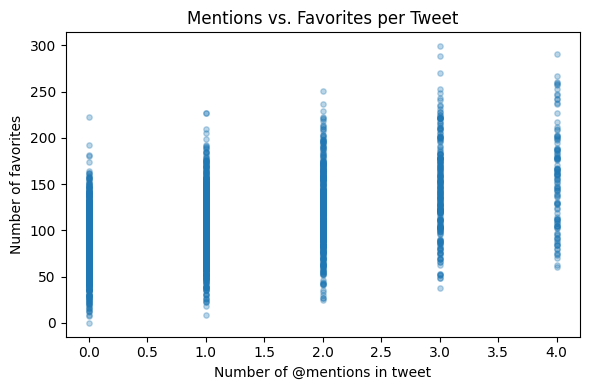

In [6]:
# --- Count mentions in each tweet --
mention_pattern = r'@\S+'
# Make sure the text column has no missing values that would break the regex
tweets['text'] = tweets['text'].fillna('')
tweets['n_mentions'] = tweets['text'].apply(
    lambda t: len(re.findall(mention_pattern, t))
)
# Quick sanity check
tweets[['text', 'n_mentions']].head(10)
# --- Correlation between mentions and favorites --
# Drop rows with missing favorite counts, just in case
valid = tweets.dropna(subset=['favorite_count', 'n_mentions'])
pearson_r, p_value = stats.pearsonr(valid['n_mentions'], valid['favorite_count'])
print(f"Pearson correlation (mentions vs. favorites): r = {pearson_r:.4f}")
print(f"p-value: {p_value:.4g}")
# Equivalent using pandas directly
corr_pandas = valid[['n_mentions', 'favorite_count']].corr().iloc[0, 1]
print(f"pandas .corr() check: {corr_pandas:.4f}")
# --- Optional: visualize the relationship --
plt.figure(figsize=(6, 4))
plt.scatter(valid['n_mentions'], valid['favorite_count'], alpha=0.3, s=15)
plt.xlabel('Number of @mentions in tweet')
plt.ylabel('Number of favorites')
plt.title('Mentions vs. Favorites per Tweet')
plt.tight_layout()
plt.show()

Part (b) — Average Mentions by Gender

Tweets successfully matched to a senator record: 2518 / 2518
        avg_mentions  median  n_tweets
gender                                
F           1.235196     1.0      1199
M           1.161486     1.0      1319


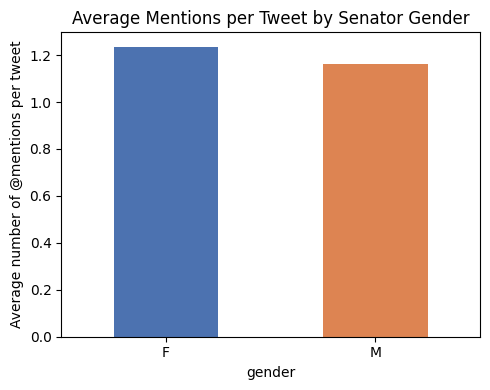

In [7]:
# --- Merge tweets with congress member info to attach gender --
# Replace 'screen_name' with whichever column is common to both
# data frames (e.g. it might be 'twitter_handle' on the congress side).
tweets['screen_name_clean'] = tweets['screen_name'].str.lower().str.strip()
congress['screen_name_clean'] = congress['twitter'].str.lower().str.strip()
merged = tweets.merge(
    congress[['screen_name_clean', 'gender']],
    on='screen_name_clean',
    how='left'
)
print(f"Tweets successfully matched to a senator record: "
      f"{merged['gender'].notna().sum()} / {len(merged)}")
# --- Average number of mentions per tweet, by gender --
avg_mentions_by_gender = (
    merged
    .dropna(subset=['gender'])
    .groupby('gender')['n_mentions']
    .agg(['mean', 'median', 'count'])
    .rename(columns={'mean': 'avg_mentions', 'count': 'n_tweets'})
)
print(avg_mentions_by_gender)
# --- Optional: visualize the comparison --
plt.figure(figsize=(5, 4))
avg_mentions_by_gender['avg_mentions'].plot(kind='bar', color=['#4c72b0', '#dd8452'])
plt.ylabel('Average number of @mentions per tweet')
plt.title('Average Mentions per Tweet by Senator Gender')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# --- Optional: statistical test for the gender difference --
groups = merged.dropna(subset=['gender'])
group_a = groups.loc[groups['gender'] == 'F', 'n_mentions']
group_b = groups.loc[groups['gender'] == 'M', 'n_mentions']
t_stat, p_val = stats.ttest_ind(group_a, group_b, equal_var=False)
print(f"t-statistic = {t_stat:.3f}, p-value = {p_val:.4g}")

t-statistic = 1.575, p-value = 0.1155
